# 09 · Fluid Benchmarking loop + V-optimal MIRT

Combines the two adaptive lines of work:

- **Fluid Benchmarking** (`cabench.adaptive_irt`, from `feat/adaptive-irt`): the adaptive loop
  `run_fluid` asks one item, reveals the answer, re-estimates θ from a warm start, and never
  repeats an item. In 1D it picks by maximum Fisher information (`select_mfi`).
- **V-optimal MIRT** (notebooks 06–07): in D dimensions, pick the item that most reduces the
  average predicted-logit variance over the item pool (Krumdick et al., Eq. 6).

Here Fluid's `run_fluid` drives the test. We only swap in two pieces through its
`select` / `estimate` hooks: the V-optimal selector and a D-dimensional MAP estimate of θ
under the training Gaussian prior (Fluid's 1D estimate uses a N(0, 1) prior).

Compared on the same family splits and budgets as the adaptive-irt script, using its
accuracy scale (mean P(correct) over every item vs true accuracy):

| Method | Model | Loop | Selector |
|---|---|---|---|
| random (1D) | `fit_2pl` | none | 20 random seeds |
| Fluid (1D) | `fit_2pl` | `run_fluid` | `select_mfi` |
| Fluid + V-optimal (MIRT) | `fit_mirt`, D from 06 | `run_fluid` | V-optimal |

In [1]:
import sys

sys.path.insert(0, "../scripts/irt")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from adaptive_run_experiment import KS, SEEDS, expected_accuracy, fluid_abilities, random_ability
from efficbench import ROOT, load
from protocol import fit_context, make_splits
from run_experiment import evaluate_scores
from scipy.special import expit

from cabench.adaptive_irt import fit_2pl, run_fluid
from cabench.design import adaptive_design, infer_theta, voptimal_gain

Y, models, items = load()
Y = Y.astype(np.float32)
splits = make_splits(Y)  # same family splits as adaptive_run_experiment.py
n_dims = int(pd.read_csv(ROOT / "results/irt/progression/mirt/chosen_dimension.csv").n_dims.iloc[0])
out = ROOT / "results/irt/progression/fluid_voptimal"
out.mkdir(parents=True, exist_ok=True)

## The two hooks

Both use the fitted MIRT's intercept form, $p_i=\sigma(\theta\cdot\alpha_i-\beta_i)$.
The selector rebuilds the posterior precision from the items asked so far, weighted at the
current θ, then takes the unused item with the largest V-optimal gain.

In [2]:
def voptimal_hooks(ctx):
    """V-optimal select and MIRT MAP estimate, with run_fluid's hook signatures."""
    precision, target, theta_train = np.linalg.inv(ctx["prior_cov"]), ctx["target"], ctx["theta"]

    def select(theta, a, b, used):
        p = expit(theta @ a.T - b)
        w = p * (1 - p)
        info = precision + (a[used] * w[used, None]).T @ a[used]
        gain = voptimal_gain(a, w, np.linalg.inv(info), target)
        gain[used] = -np.inf
        return int(np.argmax(gain))

    def estimate(answered, a, b, theta0):
        seen = np.flatnonzero(~np.isnan(answered))
        return infer_theta(answered[None, seen], seen, a, b, theta_train, initial=theta0)[0]

    return select, estimate

## Run

Per split: fit both models on train only, then run every test model up to max(k) items.
One run gives every smaller budget too. For a few models we check that the Fluid-driven run
gives the same scores as our own `adaptive_design` from 07 (item sequences match except at
near-exact ties).
Takes a while (MIRT fit plus 500 adaptive steps per test model).

In [3]:
def score(split, k, method, true, pred, seed=None):
    return {"split": split, "k": k, "method": method, "seed": seed, **evaluate_scores(true, pred)}


rows = []
for s, (train, _, test) in enumerate(splits):
    Y_test, true_acc = Y[test], Y[test].mean(1)

    # Fluid exactly as in adaptive_run_experiment.py
    a, b, theta_1d = fit_2pl(Y[train])
    fluid, _ = fluid_abilities(Y_test, a, b, theta_1d.mean(), max(KS))

    # Fluid's loop with V-optimal MIRT plugged in
    ctx = fit_context(Y[train], items.subject.values, n_dims=n_dims)
    select, estimate = voptimal_hooks(ctx)
    start = ctx["theta"].mean(0)
    alpha, beta = ctx["loadings"], ctx["beta"].astype(float)  # float64, like adaptive_design
    runs = [run_fluid(y, alpha, beta, start, max(KS), select, estimate) for y in Y_test]
    thetas = np.array([abilities for abilities, _ in runs])  # (models, max k, D)
    asked = np.array([order for _, order in runs])

    # Gains tied to ~1e-8 can flip with summation order, so compare scores, not exact items.
    _, ours, theta_ours = next(adaptive_design(Y_test[:5], ctx, [50]))
    same = (ours == asked[:5, :50]).all(1).mean()
    gap = np.abs(ctx["predict"](theta_ours).mean(1) - ctx["predict"](thetas[:5, 49]).mean(1)).max()
    print(f"split {s}: {same:.0%} identical item sequences, max score gap {100 * gap:.3f} pp")
    assert gap < 0.01, "Fluid loop and adaptive_design give different scores"

    for k in KS:
        mirt_acc = ctx["predict"](thetas[:, k - 1]).mean(1)
        rows.append(score(s, k, "Fluid (1D)", true_acc, expected_accuracy(fluid[:, k - 1], a, b)))
        rows.append(score(s, k, f"Fluid + V-optimal (D={n_dims})", true_acc, mirt_acc))
        for seed in SEEDS:
            acc = expected_accuracy(random_ability(Y_test, a, b, k, seed), a, b)
            rows.append(score(s, k, "random (1D)", true_acc, acc, seed))
    print(f"split {s} done", flush=True)

results = pd.DataFrame(rows)
results.to_csv(out / "test.csv", index=False)

split 0: 100% identical item sequences, max score gap 0.000 pp


split 0 done


split 1: 100% identical item sequences, max score gap 0.000 pp


split 1 done


split 2: 60% identical item sequences, max score gap 0.000 pp


split 2 done


split 3: 100% identical item sequences, max score gap 0.000 pp


split 3 done


split 4: 100% identical item sequences, max score gap 0.000 pp


split 4 done


## Score error

Test MAE in percentage points, ±1 SD across splits (random seeds averaged within a split first).

method,Fluid (1D),Fluid + V-optimal (D=3),random (1D)
k,,,
10,3.056259,3.704754,5.917286
20,2.668657,2.376181,4.591547
50,2.365235,1.679078,3.239619
100,2.285367,1.601186,2.617199
200,2.127136,1.474482,2.007180
500,1.944453,1.304020,1.690589


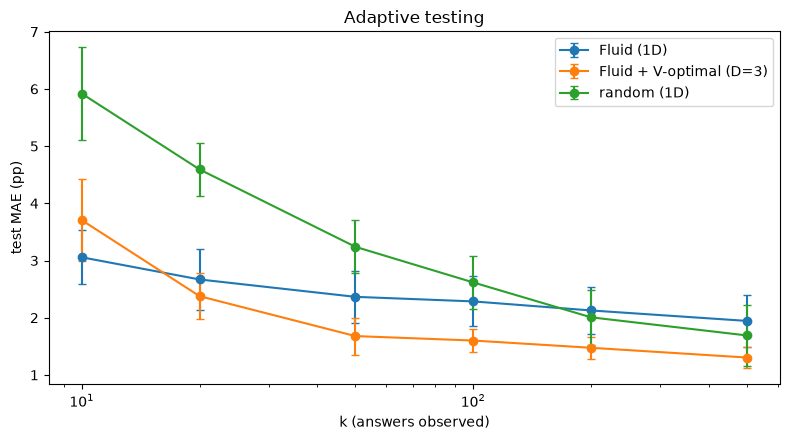

In [4]:
per_split = results.groupby(["method", "k", "split"]).mae.mean()
summary = 100 * per_split.groupby(["method", "k"]).agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(8, 4.5))
for method, curve in summary.groupby(level="method"):
    curve = curve.droplevel("method")
    ax.errorbar(curve.index, curve["mean"], yerr=curve["std"], marker="o", capsize=3, label=method)
ax.set(
    xscale="log", xlabel="k (answers observed)", ylabel="test MAE (pp)", title="Adaptive testing"
)
ax.legend()
plt.tight_layout()

summary["mean"].unstack("method")

## Context: the same design with gp-IRT

Notebook 07 ran the same adaptive V-optimal design (checked above) but scored
it with p-IRT and gp-IRT. p-IRT matches the accuracy scale here up to using the real answers
on the asked items; gp-IRT also blends in raw accuracy.

In [5]:
saved = pd.read_csv(ROOT / "results/irt/progression/voptimal/test.csv")
saved = saved[saved.method.isin(["voptimal_adaptive + p-IRT", "voptimal_adaptive + gp-IRT"])]
context = 100 * saved.groupby(["k", "method"]).mae.mean().unstack("method")
context.join(summary["mean"].unstack("method"))

method,voptimal_adaptive + gp-IRT,voptimal_adaptive + p-IRT,Fluid (1D),Fluid + V-optimal (D=3),random (1D)
k,,,,,
10,3.730777,3.704233,3.056259,3.704754,5.917286
20,2.398721,2.375231,2.668657,2.376181,4.591547
50,1.640375,1.676817,2.365235,1.679078,3.239619
100,1.568078,1.595961,2.285367,1.601186,2.617199
200,1.436562,1.463936,2.127136,1.474482,2.007180
500,1.253329,1.279741,1.944453,1.304020,1.690589


Fluid's own fit (`fit_2pl`) is still a stand-in for its hierarchical Bayesian 2PL
(see the TODO in `adaptive_irt.py`). Swapping it would change the 1D rows, not the MIRT one.